In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:

from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/DL PROJ')

print("Project folder exists:", PROJECT_DIR.exists())

if PROJECT_DIR.exists():
    print("\nFiles and folders:")
    for item in sorted(PROJECT_DIR.iterdir()):
        print(item.name)


Project folder exists: True

Files and folders:
01_HAR_Preprocessing.ipynb
Dataset
README.md
Transformers
__pycache__
cnn
har_common.py
processed


In [4]:

import sys
import numpy as np
import torch

PROJECT_DIR = "/content/drive/MyDrive/DL PROJ"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

import har_common as hc

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nLoading the shared sequence dataset...")
d = hc.load_data("sequence", channels_first=True)

print("\nDataset shapes:")
for key in [
    "X_train", "y_train",
    "X_val", "y_val",
    "X_test", "y_test",
    "subj_train", "subj_val", "subj_test"
]:
    print(f"{key}: {d[key].shape}")

print("\nClass names:", d["class_names"])
print("Dataset version:", d["meta"]["dataset_version"])

print("\nTraining data type:", d["X_train"].dtype)
print("Training labels:", np.unique(d["y_train"]))
print("Training data contains NaN:", np.isnan(d["X_train"]).any())
print("Training data contains Inf:", np.isinf(d["X_train"]).any())


PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4

Loading the shared sequence dataset...

Dataset shapes:
X_train: (5974, 9, 128)
y_train: (5974,)
X_val: (1378, 9, 128)
y_val: (1378,)
X_test: (2947, 9, 128)
y_test: (2947,)
subj_train: (5974,)
subj_val: (1378,)
subj_test: (2947,)

Class names: ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']
Dataset version: uci-har-1683f8492733

Training data type: float32
Training labels: [0 1 2 3 4 5]
Training data contains NaN: False
Training data contains Inf: False


In [5]:

import random
import time
import copy
import json
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CNN_DIR = Path(PROJECT_DIR) / "cnn"
MODEL_DIR = CNN_DIR / "final_model"
FIGURES_DIR = CNN_DIR / "figures"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Convert the shared NumPy arrays to PyTorch tensors
X_train = torch.from_numpy(d["X_train"]).float()
y_train = torch.from_numpy(d["y_train"]).long()

X_val = torch.from_numpy(d["X_val"]).float()
y_val = torch.from_numpy(d["y_val"]).long()

X_test = torch.from_numpy(d["X_test"]).float()
y_test = torch.from_numpy(d["y_test"]).long()

# Data loaders
BATCH_SIZE = 128

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

# Validation and test are not shuffled or augmented
val_loader = DataLoader(
    TensorDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Baseline 1D CNN
class HAR_CNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(9, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = HAR_CNN().to(DEVICE)

# Check input/output dimensions
sample_x, sample_y = next(iter(train_loader))
sample_x = sample_x.to(DEVICE)

with torch.no_grad():
    sample_output = model(sample_x)

print("Device:", DEVICE)
print("Input batch shape:", tuple(sample_x.shape))
print("Output shape:", tuple(sample_output.shape))
print("Total parameters:", hc.count_params(model))
print("Model ready:", isinstance(model, nn.Module))


Device: cuda
Input batch shape: (128, 9, 128)
Output shape: (128, 6)
Total parameters: 38278
Model ready: True


In [6]:

from sklearn.metrics import f1_score, accuracy_score
from torch.optim import Adam

# Baseline configuration
LEARNING_RATE = 0.001
MAX_EPOCHS = 100
PATIENCE = 20

criterion = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=LEARNING_RATE)

baseline_weights_path = MODEL_DIR / "cnn_baseline_weights.pt"
baseline_history_path = CNN_DIR / "training_history_baseline.csv"

best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0
history = []

start_time = time.perf_counter()

def evaluate_epoch(model, loader):
    model.eval()
    total_loss = 0.0
    all_y = []
    all_pred = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            logits = model(xb)
            loss = criterion(logits, yb)

            total_loss += loss.item() * len(yb)
            all_y.extend(yb.cpu().numpy())
            all_pred.extend(logits.argmax(dim=1).cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_y, all_pred)
    macro_f1 = f1_score(
        all_y, all_pred,
        average="macro",
        zero_division=0
    )

    return avg_loss, acc, macro_f1

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.perf_counter()

    model.train()
    train_loss_sum = 0.0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(xb)
        loss = criterion(logits, yb)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(yb)

    train_time_loss = train_loss_sum / len(train_loader.dataset)

    # Evaluate with dropout disabled
    train_loss, train_acc, train_f1 = evaluate_epoch(
        model, train_loader
    )
    val_loss, val_acc, val_f1 = evaluate_epoch(
        model, val_loader
    )

    epoch_time = time.perf_counter() - epoch_start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_macro_f1": val_f1,
        "lr": optimizer.param_groups[0]["lr"],
        "epoch_time_s": epoch_time
    })

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(model.state_dict(), baseline_weights_path)
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0 or val_f1 == best_val_f1:
        print(
            f"Epoch {epoch:03d} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_acc:.4f} | "
            f"Val macro-F1: {val_f1:.4f}"
        )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

total_train_time = time.perf_counter() - start_time

# Save baseline training history
history_df = pd.DataFrame(history)
history_df.to_csv(baseline_history_path, index=False)

# Restore the best validation macro-F1 checkpoint
model.load_state_dict(
    torch.load(baseline_weights_path, map_location=DEVICE, weights_only=True)
)
model.eval()

print("\nBaseline training complete.")
print("Best epoch:", best_epoch)
print(f"Best validation macro-F1: {best_val_f1:.4f}")
print(f"Total training time: {total_train_time:.2f} seconds")
print("Weights saved:", baseline_weights_path)
print("History saved:", baseline_history_path)


Epoch 001 | Train loss: 0.2252 | Val loss: 0.2165 | Val accuracy: 0.9405 | Val macro-F1: 0.9434
Epoch 002 | Train loss: 0.1381 | Val loss: 0.1368 | Val accuracy: 0.9521 | Val macro-F1: 0.9544
Epoch 004 | Train loss: 0.1144 | Val loss: 0.1023 | Val accuracy: 0.9579 | Val macro-F1: 0.9605
Epoch 005 | Train loss: 0.1104 | Val loss: 0.1128 | Val accuracy: 0.9434 | Val macro-F1: 0.9464
Epoch 008 | Train loss: 0.1022 | Val loss: 0.0964 | Val accuracy: 0.9586 | Val macro-F1: 0.9613
Epoch 010 | Train loss: 0.0998 | Val loss: 0.0927 | Val accuracy: 0.9565 | Val macro-F1: 0.9591
Epoch 015 | Train loss: 0.0962 | Val loss: 0.0770 | Val accuracy: 0.9710 | Val macro-F1: 0.9729
Epoch 020 | Train loss: 0.0940 | Val loss: 0.0835 | Val accuracy: 0.9695 | Val macro-F1: 0.9713
Epoch 025 | Train loss: 0.0658 | Val loss: 0.0866 | Val accuracy: 0.9478 | Val macro-F1: 0.9506
Epoch 030 | Train loss: 0.0697 | Val loss: 0.0859 | Val accuracy: 0.9550 | Val macro-F1: 0.9574
Epoch 035 | Train loss: 0.0589 | Val los

In [7]:

# ============================================================
# STEP 6: CNN HYPERPARAMETER TUNING
# ============================================================

import gc
import json
import time
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import TensorDataset, DataLoader

# Tuning configurations
CONFIGS = [
    {"optimizer": "Adam",  "lr": 0.001,  "batch_size": 128, "weight_decay": 0.0},
    {"optimizer": "Adam",  "lr": 0.0005, "batch_size": 128, "weight_decay": 0.0001},
    {"optimizer": "Adam",  "lr": 0.001,  "batch_size": 64,  "weight_decay": 0.0001},
    {"optimizer": "AdamW", "lr": 0.0005, "batch_size": 64,  "weight_decay": 0.0001},
]

MAX_TUNING_EPOCHS = 200
TUNING_PATIENCE = 20

grid_rows = []
best_overall_f1 = -1.0
best_config = None
best_tuned_epoch = None
best_tuned_history = None

tuning_start = time.perf_counter()

# ------------------------------------------------------------
# Run each configuration independently
# ------------------------------------------------------------

for trial_idx, cfg in enumerate(CONFIGS, start=1):

    print(f"\n{'=' * 55}")
    print(f"Trial {trial_idx}/{len(CONFIGS)}: {cfg}")
    print("=" * 55)

    # Reproducibility
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    # Fresh model for this trial
    trial_model = HAR_CNN().to(DEVICE)

    if cfg["optimizer"] == "Adam":
        trial_optimizer = torch.optim.Adam(
            trial_model.parameters(),
            lr=cfg["lr"],
            weight_decay=cfg["weight_decay"]
        )
    else:
        trial_optimizer = torch.optim.AdamW(
            trial_model.parameters(),
            lr=cfg["lr"],
            weight_decay=cfg["weight_decay"]
        )

    trial_train_loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=cfg["batch_size"],
        shuffle=True,
        num_workers=0
    )

    trial_best_f1 = -1.0
    trial_best_acc = 0.0
    trial_best_epoch = 0
    trial_wait = 0
    trial_history = []

    trial_start = time.perf_counter()

    trial_weights_path = (
        MODEL_DIR / f"cnn_trial_{trial_idx}_weights.pt"
    )

    # --------------------------------------------------------
    # Training loop with early stopping
    # --------------------------------------------------------

    for epoch in range(1, MAX_TUNING_EPOCHS + 1):

        epoch_start = time.perf_counter()
        trial_model.train()

        for xb, yb in trial_train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            trial_optimizer.zero_grad(set_to_none=True)

            logits = trial_model(xb)
            loss = criterion(logits, yb)

            loss.backward()
            trial_optimizer.step()

        # Evaluate train and validation data in eval mode
        tr_loss, tr_acc, tr_f1 = evaluate_epoch(
            trial_model, trial_train_loader
        )

        va_loss, va_acc, va_f1 = evaluate_epoch(
            trial_model, val_loader
        )

        epoch_time = time.perf_counter() - epoch_start

        trial_history.append({
            "epoch": epoch,
            "train_loss": tr_loss,
            "train_acc": tr_acc,
            "train_macro_f1": tr_f1,
            "val_loss": va_loss,
            "val_acc": va_acc,
            "val_macro_f1": va_f1,
            "lr": trial_optimizer.param_groups[0]["lr"],
            "epoch_time_s": epoch_time
        })

        # Select checkpoint by validation macro-F1
        if va_f1 > trial_best_f1:

            trial_best_f1 = va_f1
            trial_best_acc = va_acc
            trial_best_epoch = epoch
            trial_wait = 0

            # Save a copy of the best weights
            torch.save(
                trial_model.state_dict(),
                trial_weights_path
            )

        else:
            trial_wait += 1

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Epoch {epoch:03d} | "
                f"Train F1: {tr_f1:.4f} | "
                f"Val F1: {va_f1:.4f} | "
                f"Best Val F1: {trial_best_f1:.4f}"
            )

        if trial_wait >= TUNING_PATIENCE:
            print(f"Early stopping at epoch {epoch}.")
            break

    trial_time = time.perf_counter() - trial_start
    epochs_trained = len(trial_history)

    # Record this configuration's best validation results
    grid_rows.append({
        "trial": trial_idx,
        "optimizer": cfg["optimizer"],
        "lr": cfg["lr"],
        "batch_size": cfg["batch_size"],
        "weight_decay": cfg["weight_decay"],
        "val_macro_f1": trial_best_f1,
        "val_acc": trial_best_acc,
        "best_epoch": trial_best_epoch,
        "epochs_trained": epochs_trained,
        "train_time_s": trial_time
    })

    print(f"\nTrial {trial_idx} best validation macro-F1: "
          f"{trial_best_f1:.4f}")
    print(f"Best epoch: {trial_best_epoch}")

    # Keep the best configuration across all trials
    if trial_best_f1 > best_overall_f1:

        best_overall_f1 = trial_best_f1
        best_config = cfg.copy()
        best_tuned_epoch = trial_best_epoch
        best_tuned_history = trial_history.copy()

        # Load the best checkpoint from this trial and preserve it
        best_state = torch.load(
            trial_weights_path,
            map_location="cpu",
            weights_only=True
        )

        torch.save(
            best_state,
            MODEL_DIR / "cnn_tuned_weights.pt"
        )

    del trial_model, trial_optimizer, trial_train_loader
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# SAVE TUNING RESULTS AND FINAL CONFIGURATION
# ============================================================

grid_df = pd.DataFrame(grid_rows)

grid_df.to_csv(
    CNN_DIR / "grid_search_results.csv",
    index=False
)

with open(MODEL_DIR / "config.json", "w") as f:
    json.dump({
        "model": "HAR_CNN",
        "input_shape": [9, 128],
        "num_classes": 6,
        "seed": SEED,
        "best_epoch": best_tuned_epoch,
        "best_validation_macro_f1": best_overall_f1,
        **best_config
    }, f, indent=2)

# Save history for the selected tuned configuration
pd.DataFrame(best_tuned_history).to_csv(
    CNN_DIR / "training_history_final.csv",
    index=False
)

total_tuning_time = time.perf_counter() - tuning_start

print("\n" + "=" * 55)
print("HYPERPARAMETER TUNING COMPLETE")
print("=" * 55)

print("\nAll trial results:")
print(grid_df.to_string(index=False))

print("\nSelected configuration:")
print(json.dumps(best_config, indent=2))

print(f"\nBest validation macro-F1: {best_overall_f1:.4f}")
print(f"Selected epoch: {best_tuned_epoch}")
print(f"Total tuning time: {total_tuning_time:.2f} seconds")

print("\nSaved files:")
print("Tuned weights:", MODEL_DIR / "cnn_tuned_weights.pt")
print("Configuration:", MODEL_DIR / "config.json")
print("Grid results:", CNN_DIR / "grid_search_results.csv")
print("Training history:", CNN_DIR / "training_history_final.csv")



Trial 1/4: {'optimizer': 'Adam', 'lr': 0.001, 'batch_size': 128, 'weight_decay': 0.0}
Epoch 001 | Train F1: 0.9447 | Val F1: 0.9582 | Best Val F1: 0.9582
Epoch 010 | Train F1: 0.9629 | Val F1: 0.9613 | Best Val F1: 0.9623
Epoch 020 | Train F1: 0.9707 | Val F1: 0.9523 | Best Val F1: 0.9695
Epoch 030 | Train F1: 0.9741 | Val F1: 0.9493 | Best Val F1: 0.9695
Early stopping at epoch 38.

Trial 1 best validation macro-F1: 0.9695
Best epoch: 18

Trial 2/4: {'optimizer': 'Adam', 'lr': 0.0005, 'batch_size': 128, 'weight_decay': 0.0001}
Epoch 001 | Train F1: 0.9265 | Val F1: 0.9540 | Best Val F1: 0.9540
Epoch 010 | Train F1: 0.9619 | Val F1: 0.9605 | Best Val F1: 0.9613
Epoch 020 | Train F1: 0.9626 | Val F1: 0.9681 | Best Val F1: 0.9681
Epoch 030 | Train F1: 0.9718 | Val F1: 0.9515 | Best Val F1: 0.9681
Epoch 040 | Train F1: 0.9743 | Val F1: 0.9516 | Best Val F1: 0.9681
Early stopping at epoch 40.

Trial 2 best validation macro-F1: 0.9681
Best epoch: 20

Trial 3/4: {'optimizer': 'Adam', 'lr': 

In [8]:
from pathlib import Path
import json
import pandas as pd

CNN_DIR = Path("/content/drive/MyDrive/DL PROJ/cnn")
MODEL_DIR = CNN_DIR / "final_model"

required_files = [
    MODEL_DIR / "cnn_tuned_weights.pt",
    MODEL_DIR / "cnn_baseline_weights.pt",
    MODEL_DIR / "config.json",
    CNN_DIR / "grid_search_results.csv",
    CNN_DIR / "training_history_baseline.csv",
    CNN_DIR / "training_history_final.csv",
]

print("FILE VERIFICATION")
for file in required_files:
    print(f"{'OK' if file.exists() else 'MISSING'}: {file.name}")

print("\nSAVED CONFIGURATION")
with open(MODEL_DIR / "config.json", "r") as f:
    print(json.dumps(json.load(f), indent=2))

print("\nGRID SEARCH RESULTS")
display(pd.read_csv(CNN_DIR / "grid_search_results.csv"))

FILE VERIFICATION
OK: cnn_tuned_weights.pt
OK: cnn_baseline_weights.pt
OK: config.json
OK: grid_search_results.csv
OK: training_history_baseline.csv
OK: training_history_final.csv

SAVED CONFIGURATION
{
  "model": "HAR_CNN",
  "input_shape": [
    9,
    128
  ],
  "num_classes": 6,
  "seed": 42,
  "best_epoch": 17,
  "best_validation_macro_f1": 0.9769643889944643,
  "optimizer": "AdamW",
  "lr": 0.0005,
  "batch_size": 64,
  "weight_decay": 0.0001
}

GRID SEARCH RESULTS


,trial,optimizer,lr,batch_size,weight_decay,val_macro_f1,val_acc,best_epoch,epochs_trained,train_time_s
0,1,Adam,0.0010,128,0.0000,0.969491,0.967344,18,38,14.480025
1,2,Adam,0.0005,128,0.0001,0.968119,0.965893,20,40,13.880059
2,3,Adam,0.0010,64,0.0001,0.966657,0.964441,26,46,26.194604
3,4,AdamW,0.0005,64,0.0001,0.976964,0.975327,17,37,21.972202


In [9]:

# Final checkpoint verification on the validation set only

import torch
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

# Recreate the model architecture and load the selected checkpoint
final_model = HAR_CNN().to(DEVICE)

checkpoint = torch.load(
    MODEL_DIR / "cnn_tuned_weights.pt",
    map_location=DEVICE,
    weights_only=True
)
final_model.load_state_dict(checkpoint)
final_model.eval()

# Validation predictions
val_probs_list = []
val_labels_list = []

with torch.no_grad():
    for xb, yb in val_loader:
        xb = xb.to(DEVICE)
        logits = final_model(xb)
        probs = torch.softmax(logits, dim=1)

        val_probs_list.append(probs.cpu().numpy())
        val_labels_list.append(yb.numpy())

P_val_check = np.concatenate(val_probs_list, axis=0)
y_val_check = np.concatenate(val_labels_list, axis=0)
y_val_pred = P_val_check.argmax(axis=1)

print("Checkpoint loaded successfully.")
print(f"Validation accuracy: {accuracy_score(y_val_check, y_val_pred):.4f}")
print(f"Validation macro-F1: {f1_score(y_val_check, y_val_pred, average='macro'):.4f}")
print("Validation probability shape:", P_val_check.shape)


Checkpoint loaded successfully.
Validation accuracy: 0.9753
Validation macro-F1: 0.9770
Validation probability shape: (1378, 6)


In [10]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json

# Use the selected tuned checkpoint
final_model.eval()

# Generate test predictions
test_probs_list = []
test_labels_list = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        probs = torch.softmax(final_model(xb), dim=1)

        test_probs_list.append(probs.cpu().numpy())
        test_labels_list.append(yb.numpy())

P_test = np.concatenate(test_probs_list, axis=0)
y_test_eval = np.concatenate(test_labels_list, axis=0)
y_test_pred = P_test.argmax(axis=1)

# Keep the original official test-subject IDs
subj_test = np.asarray(d["subj_test"])

# Create output folders
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 1. Classification report
class_names = d["class_names"]

report = classification_report(
    y_test_eval,
    y_test_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
)

with open(CNN_DIR / "classification_report_test.txt", "w") as f:
    f.write(report)

print("TEST SET RESULTS")
print("================")
print(f"Test accuracy: {accuracy_score(y_test_eval, y_test_pred):.4f}")
print(f"Test macro-F1: {f1_score(y_test_eval, y_test_pred, average='macro'):.4f}")
print("\nClassification report:")
print(report)

# 2. Confusion matrix
cm = confusion_matrix(
    y_test_eval,
    y_test_pred,
    labels=np.arange(len(class_names))
)

hc.plot_confusion_matrix(
    cm,
    class_names,
    save_path=str(FIGURES_DIR / "confusion_matrix_test.png")
)

# 3. Per-subject accuracy
subject_rows = []
for subject in np.unique(subj_test):
    mask = subj_test == subject
    subject_rows.append({
        "subject": subject,
        "samples": int(mask.sum()),
        "accuracy": accuracy_score(y_test_eval[mask], y_test_pred[mask])
    })

subject_df = pd.DataFrame(subject_rows)
subject_df.to_csv(
    CNN_DIR / "per_subject_accuracy_test.csv",
    index=False
)

# 4. Save predictions for later metric generation
np.savez_compressed(
    MODEL_DIR / "predictions.npz",
    P_val=P_val_check,
    P_test=P_test,
    y_test=y_test_eval,
    subj_test=subj_test
)

print("\nPer-subject accuracy:")
display(subject_df)

print("\nSaved:")
print(CNN_DIR / "classification_report_test.txt")
print(FIGURES_DIR / "confusion_matrix_test.png")
print(CNN_DIR / "per_subject_accuracy_test.csv")
print(MODEL_DIR / "predictions.npz")


TEST SET RESULTS
Test accuracy: 0.9511
Test macro-F1: 0.9525

Classification report:
                    precision    recall  f1-score   support

           WALKING     0.9980    1.0000    0.9990       496
  WALKING_UPSTAIRS     0.9792    0.9979    0.9884       471
WALKING_DOWNSTAIRS     0.9976    0.9976    0.9976       420
           SITTING     0.8628    0.8452    0.8539       491
          STANDING     0.8759    0.8759    0.8759       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.9511      2947
         macro avg     0.9522    0.9528    0.9525      2947
      weighted avg     0.9507    0.9511    0.9509      2947



TypeError: plot_confusion_matrix() got an unexpected keyword argument 'save_path'

Saved confusion_matrix_test.png


,subject,samples,accuracy
0,2,302,0.890728
1,4,317,0.971609
2,9,288,0.836806
3,10,294,0.823129
4,12,320,1.000000
5,13,327,1.000000
6,18,364,1.000000
7,20,354,0.994350
8,24,381,0.997375


Saved per_subject_accuracy_test.csv
Saved predictions.npz
P_train: (5974, 6)
P_val: (1378, 6)
P_test: (2947, 6)
OK classification_report_test.txt
OK per_subject_accuracy_test.csv
OK confusion_matrix_test.png
OK predictions.npz


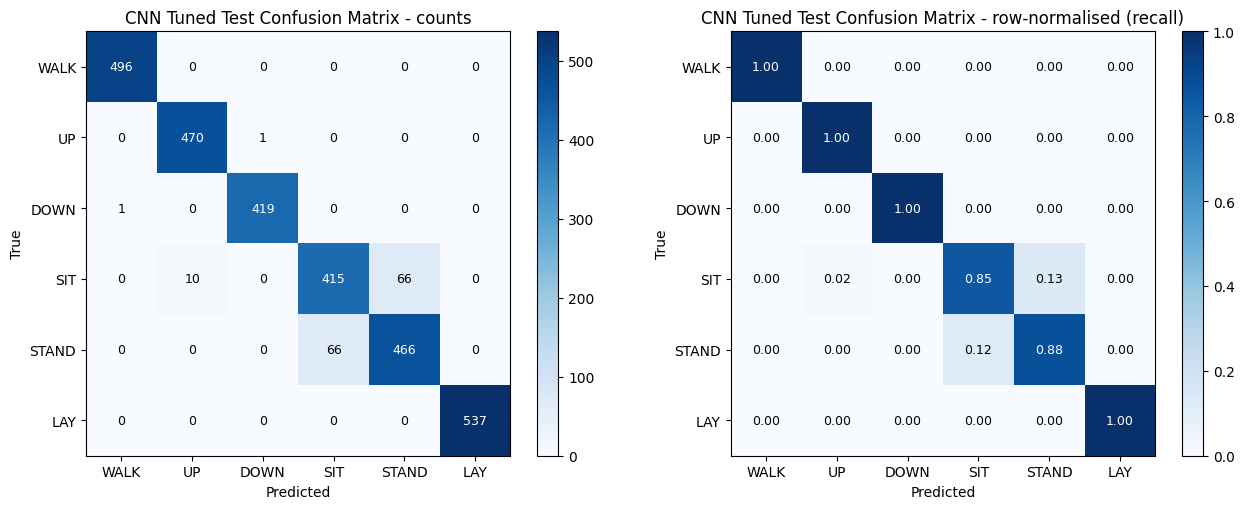

In [11]:

# Resume saving outputs without evaluating the test set again

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score
from pathlib import Path

MODEL_DIR = CNN_DIR / "final_model"
FIGURES_DIR = CNN_DIR / "figures"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 1. Confusion matrix using the helper's actual signature
hc.plot_confusion_matrix(
    y_test_eval,
    y_test_pred,
    path=str(FIGURES_DIR / "confusion_matrix_test.png"),
    title="CNN Tuned Test Confusion Matrix"
)
print("Saved confusion_matrix_test.png")

# 2. Per-subject test accuracy, using existing predictions
subj_test = np.asarray(d["subj_test"])
subject_rows = []

for subject in np.unique(subj_test):
    mask = subj_test == subject
    subject_rows.append({
        "subject": subject,
        "samples": int(mask.sum()),
        "accuracy": accuracy_score(y_test_eval[mask], y_test_pred[mask])
    })

subject_df = pd.DataFrame(subject_rows)
subject_df.to_csv(CNN_DIR / "per_subject_accuracy_test.csv", index=False)
display(subject_df)
print("Saved per_subject_accuracy_test.csv")

# 3. Generate training probabilities only (no test-set evaluation)
final_model.eval()
train_probs_list = []

with torch.no_grad():
    for xb, _ in train_loader:
        xb = xb.to(DEVICE)
        probs = torch.softmax(final_model(xb), dim=1)
        train_probs_list.append(probs.cpu().numpy())

P_train = np.concatenate(train_probs_list, axis=0)

# 4. Save predictions for downstream metric generation
np.savez_compressed(
    MODEL_DIR / "predictions.npz",
    P_train=P_train,
    P_val=P_val_check,
    P_test=P_test,
    y_test=y_test_eval,
    subj_test=subj_test
)
print("Saved predictions.npz")
print("P_train:", P_train.shape)
print("P_val:", P_val_check.shape)
print("P_test:", P_test.shape)

# 5. Confirm the principal outputs exist
for path in [
    CNN_DIR / "classification_report_test.txt",
    CNN_DIR / "per_subject_accuracy_test.csv",
    FIGURES_DIR / "confusion_matrix_test.png",
    MODEL_DIR / "predictions.npz"
]:
    print(("OK" if path.exists() else "MISSING"), path.name)


Saved validation confusion matrix.
Updated predictions.npz.
Next, we will populate cnn_results.csv through hc.save_results.


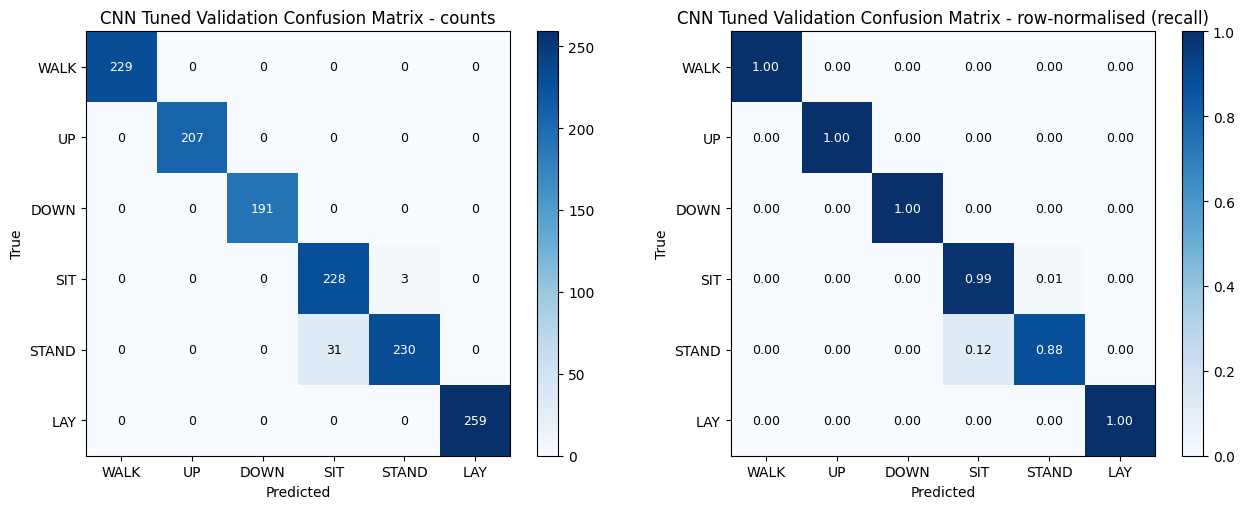

In [12]:

# Generate standard metrics for the tuned CNN using har_common.py

import time
import numpy as np
import torch
from pathlib import Path

# Load the best tuned checkpoint again to ensure the correct model is active
final_model = HAR_CNN().to(DEVICE)
final_model.load_state_dict(
    torch.load(
        MODEL_DIR / "cnn_tuned_weights.pt",
        map_location=DEVICE,
        weights_only=True
    )
)
final_model.eval()

# Collect validation labels and probabilities from the verified checkpoint
# (This is validation evaluation, not another test evaluation.)
val_probs_list = []
val_labels_list = []

with torch.no_grad():
    for xb, yb in val_loader:
        probs = torch.softmax(final_model(xb.to(DEVICE)), dim=1)
        val_probs_list.append(probs.cpu().numpy())
        val_labels_list.append(yb.numpy())

P_val = np.concatenate(val_probs_list)
y_val_final = np.concatenate(val_labels_list)

# Prepare arrays for the shared results helper
y_train_np = np.asarray(d["y_train"])
y_val_np = np.asarray(d["y_val"])
y_test_np = np.asarray(d["y_test"])

# Save validation confusion matrix using the helper's actual signature
hc.plot_confusion_matrix(
    y_val_np,
    P_val.argmax(axis=1),
    path=str(FIGURES_DIR / "confusion_matrix_val.png"),
    title="CNN Tuned Validation Confusion Matrix"
)

# Save the prediction archive with all required arrays
np.savez_compressed(
    MODEL_DIR / "predictions.npz",
    P_train=P_train,
    P_val=P_val,
    P_test=P_test,
    y_test=y_test_np,
    subj_test=np.asarray(d["subj_test"])
)

print("Saved validation confusion matrix.")
print("Updated predictions.npz.")
print("Next, we will populate cnn_results.csv through hc.save_results.")


In [13]:

# Save tuned CNN results using the shared project helper

import numpy as np
import pandas as pd

results_path = CNN_DIR / "cnn_results.csv"

# Use the probabilities already generated by the tuned checkpoint
result_row = hc.save_results(
    str(results_path),
    model_name="cnn",
    family="CNN",
    owner="Akshaj Vinod Chandak",
    input_representation="raw_9ch_128",
    run_tag="tuned",
    y_train=np.asarray(d["y_train"]),
    proba_train=P_train,
    y_val=np.asarray(d["y_val"]),
    proba_val=P_val,
    y_test=np.asarray(d["y_test"]),
    proba_test=P_test,
    subj_test=np.asarray(d["subj_test"]),
    seed=42,
    notes="Tuned 1D CNN; selected using validation macro-F1. AdamW, lr=0.0005, batch_size=64, weight_decay=0.0001; best epoch 17."
)

print("Saved:", results_path)
print("\nKey metrics:")
for key in [
    "test_accuracy",
    "test_macro_f1",
    "test_balanced_accuracy",
    "test_weighted_f1",
    "test_mcc",
    "test_cohen_kappa"
]:
    if key in result_row:
        print(f"{key}: {result_row[key]}")

print("\nSaved CSV shape:", pd.read_csv(results_path).shape)
print("Saved columns:", len(pd.read_csv(results_path).columns))


Saved: /content/drive/MyDrive/DL PROJ/cnn/cnn_results.csv

Key metrics:
test_accuracy: 0.9511367492365117
test_macro_f1: 0.9524824235165213
test_balanced_accuracy: 0.9527749340466243
test_weighted_f1: 0.9509067191458981
test_mcc: 0.9413022287629195
test_cohen_kappa: 0.9412903781868177

Saved CSV shape: (1, 48)
Saved columns: 48


Baseline history columns: ['epoch', 'train_loss', 'train_acc', 'train_macro_f1', 'val_loss', 'val_acc', 'val_macro_f1', 'lr', 'epoch_time_s']
Tuned history columns: ['epoch', 'train_loss', 'train_acc', 'train_macro_f1', 'val_loss', 'val_acc', 'val_macro_f1', 'lr', 'epoch_time_s']


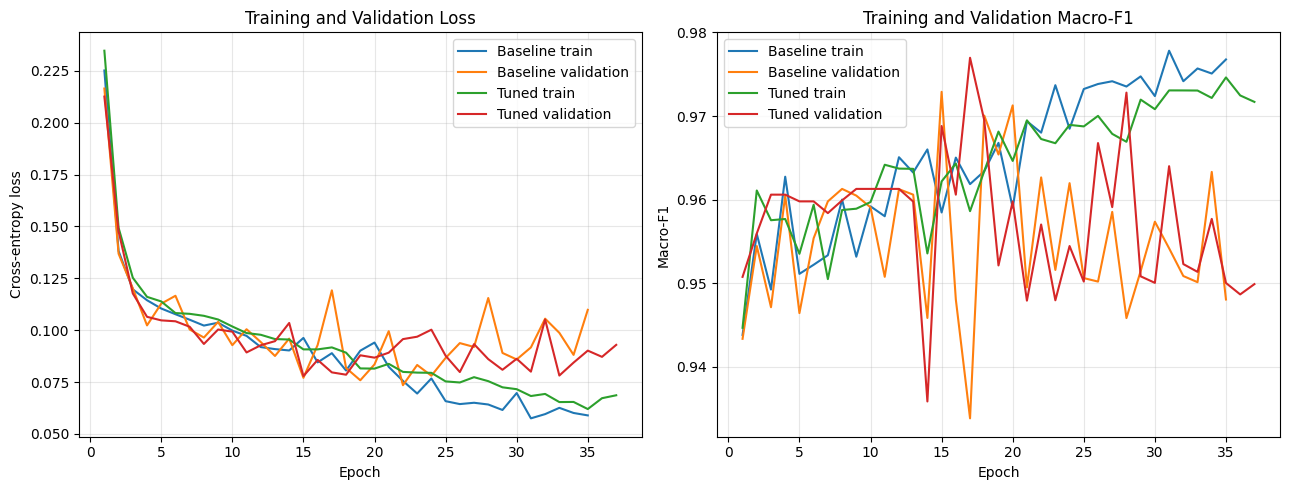

Saved: /content/drive/MyDrive/DL PROJ/cnn/figures/baseline_vs_tuned_curves.png


In [14]:

import pandas as pd
import matplotlib.pyplot as plt

baseline_history_path = CNN_DIR / "training_history_baseline.csv"
final_history_path = CNN_DIR / "training_history_final.csv"

baseline_history = pd.read_csv(baseline_history_path)
final_history = pd.read_csv(final_history_path)

print("Baseline history columns:", baseline_history.columns.tolist())
print("Tuned history columns:", final_history.columns.tolist())

# Plot loss curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    baseline_history["epoch"],
    baseline_history["train_loss"],
    label="Baseline train"
)
axes[0].plot(
    baseline_history["epoch"],
    baseline_history["val_loss"],
    label="Baseline validation"
)
axes[0].plot(
    final_history["epoch"],
    final_history["train_loss"],
    label="Tuned train"
)
axes[0].plot(
    final_history["epoch"],
    final_history["val_loss"],
    label="Tuned validation"
)
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot macro-F1 curves
axes[1].plot(
    baseline_history["epoch"],
    baseline_history["train_macro_f1"],
    label="Baseline train"
)
axes[1].plot(
    baseline_history["epoch"],
    baseline_history["val_macro_f1"],
    label="Baseline validation"
)
axes[1].plot(
    final_history["epoch"],
    final_history["train_macro_f1"],
    label="Tuned train"
)
axes[1].plot(
    final_history["epoch"],
    final_history["val_macro_f1"],
    label="Tuned validation"
)
axes[1].set_title("Training and Validation Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "baseline_vs_tuned_curves.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Saved:", FIGURES_DIR / "baseline_vs_tuned_curves.png")


In [15]:

import time
import json
import numpy as np
import torch

# Ensure the tuned model is loaded
final_model.eval()

# Parameter count
param_count = hc.count_params(final_model)

# Model file size
model_path = MODEL_DIR / "cnn_tuned_weights.pt"
model_size_mb = hc.file_size_mb(str(model_path))

# FLOPs using the model's actual input shape: (1, 9, 128)
try:
    flops = hc.count_flops(final_model, (1, 9, 128), device=DEVICE)
except TypeError:
    flops = hc.count_flops(final_model, (1, 9, 128))

# CPU latency and throughput
cpu_model = HAR_CNN().cpu()
cpu_model.load_state_dict(
    torch.load(model_path, map_location="cpu", weights_only=True)
)
cpu_model.eval()

try:
    latency = hc.measure_latency(cpu_model, (1, 9, 128))
except TypeError:
    latency = hc.measure_latency(cpu_model, input_shape=(1, 9, 128))

try:
    throughput = hc.measure_throughput(cpu_model, (9, 128))
except TypeError:
    throughput = hc.measure_throughput(cpu_model, input_shape=(9, 128))

efficiency = {
    "parameters": int(param_count),
    "model_size_mb": float(model_size_mb),
    "flops": str(flops),
    "cpu_latency": str(latency),
    "cpu_throughput": str(throughput),
    "hardware": hc.hardware_string(),
    "framework": hc.framework_string()
}

print(json.dumps(efficiency, indent=2))

with open(MODEL_DIR / "efficiency_metrics.json", "w") as f:
    json.dump(efficiency, f, indent=2)

print("\nSaved:", MODEL_DIR / "efficiency_metrics.json")


{
  "parameters": 38278,
  "model_size_mb": 0.15557861328125,
  "flops": "3401216.0",
  "cpu_latency": "1.8387282499998037",
  "cpu_throughput": "105238.02020123528",
  "hardware": "GPU: Tesla T4; CPU: x86_64",
  "framework": "PyTorch 2.11.0+cu130"
}

Saved: /content/drive/MyDrive/DL PROJ/cnn/final_model/efficiency_metrics.json


In [16]:

from pathlib import Path

required_paths = [
    CNN_DIR / "cnn_results.csv",
    CNN_DIR / "training_history_final.csv",
    CNN_DIR / "classification_report_test.txt",
    CNN_DIR / "per_subject_accuracy_test.csv",
    CNN_DIR / "grid_search_results.csv",
    CNN_DIR / "baseline_vs_tuned_test.csv",
    FIGURES_DIR / "learning_curves_final.png",
    FIGURES_DIR / "confusion_matrix_test.png",
    FIGURES_DIR / "confusion_matrix_val.png",
    FIGURES_DIR / "per_subject_and_per_class.png",
    FIGURES_DIR / "baseline_vs_tuned_curves.png",
    MODEL_DIR / "predictions.npz",
    MODEL_DIR / "cnn_tuned_weights.pt",
    MODEL_DIR / "config.json",
    MODEL_DIR / "efficiency_metrics.json",
]

print("CNN SUBMISSION FILE CHECK")
print("=" * 45)

for path in required_paths:
    print(f"{'OK      ' if path.exists() else 'MISSING '} {path.relative_to(CNN_DIR)}")

print("\nAll files currently inside cnn/:")
for path in sorted(CNN_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(CNN_DIR))


CNN SUBMISSION FILE CHECK
OK       cnn_results.csv
OK       training_history_final.csv
OK       classification_report_test.txt
OK       per_subject_accuracy_test.csv
OK       grid_search_results.csv
MISSING  baseline_vs_tuned_test.csv
MISSING  figures/learning_curves_final.png
OK       figures/confusion_matrix_test.png
OK       figures/confusion_matrix_val.png
MISSING  figures/per_subject_and_per_class.png
OK       figures/baseline_vs_tuned_curves.png
OK       final_model/predictions.npz
OK       final_model/cnn_tuned_weights.pt
OK       final_model/config.json
OK       final_model/efficiency_metrics.json

All files currently inside cnn/:
classification_report_test.txt
cnn_results.csv
figures/baseline_vs_tuned_curves.png
figures/confusion_matrix_test.png
figures/confusion_matrix_val.png
final_model/cnn_baseline_weights.pt
final_model/cnn_trial_1_weights.pt
final_model/cnn_trial_2_weights.pt
final_model/cnn_trial_3_weights.pt
final_model/cnn_trial_4_weights.pt
final_model/cnn_tuned_weig

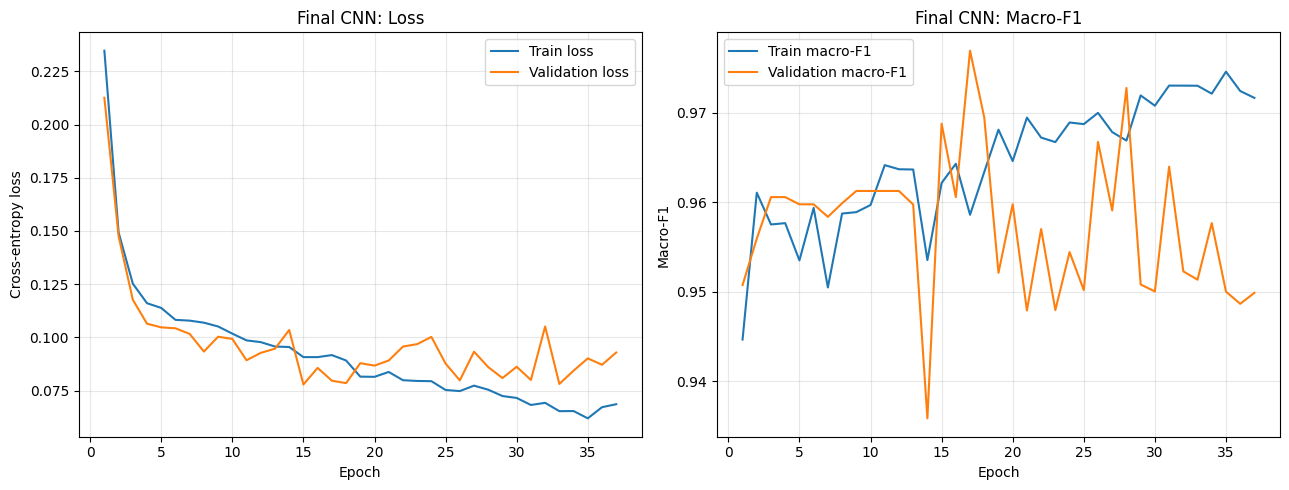

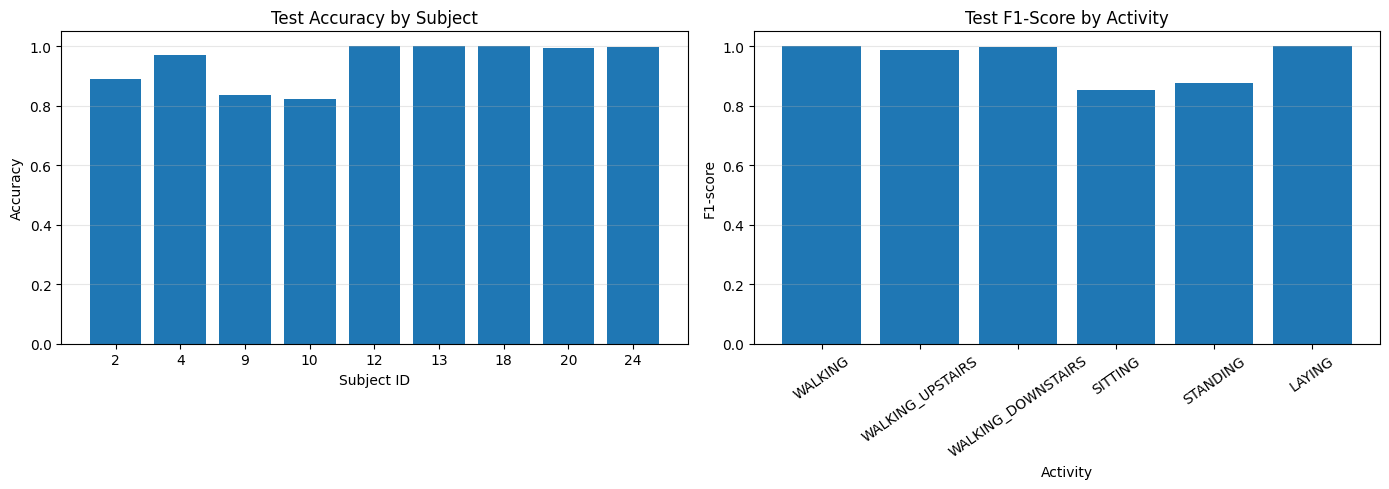

Saved learning_curves_final.png
Saved per_subject_and_per_class.png


In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# Load saved histories and per-subject results
history = pd.read_csv(CNN_DIR / "training_history_final.csv")
subject_df = pd.read_csv(CNN_DIR / "per_subject_accuracy_test.csv")

# Load the already-saved test predictions (no new inference)
saved = np.load(MODEL_DIR / "predictions.npz")
y_test_saved = saved["y_test"]
P_test_saved = saved["P_test"]
y_test_pred_saved = P_test_saved.argmax(axis=1)

class_names = d["class_names"]
y_test_true = np.asarray(d["y_test"])

# 1. Final tuned-model learning curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history["epoch"], history["train_loss"], label="Train loss")
axes[0].plot(history["epoch"], history["val_loss"], label="Validation loss")
axes[0].set_title("Final CNN: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history["epoch"], history["train_macro_f1"], label="Train macro-F1")
axes[1].plot(history["epoch"], history["val_macro_f1"], label="Validation macro-F1")
axes[1].set_title("Final CNN: Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "learning_curves_final.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 2. Per-subject accuracy and per-class test F1
per_class_f1 = f1_score(
    y_test_true,
    y_test_pred_saved,
    labels=np.arange(len(class_names)),
    average=None,
    zero_division=0
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    subject_df["subject"].astype(str),
    subject_df["accuracy"]
)
axes[0].set_title("Test Accuracy by Subject")
axes[0].set_xlabel("Subject ID")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1.05)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(class_names, per_class_f1)
axes[1].set_title("Test F1-Score by Activity")
axes[1].set_xlabel("Activity")
axes[1].set_ylabel("F1-score")
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis="x", rotation=35)
axes[1].grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "per_subject_and_per_class.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved learning_curves_final.png")
print("Saved per_subject_and_per_class.png")


In [18]:

import pandas as pd
import json

# Read the saved histories and tuning results
baseline_history = pd.read_csv(CNN_DIR / "training_history_baseline.csv")
tuning_results = pd.read_csv(CNN_DIR / "grid_search_results.csv")
final_history = pd.read_csv(CNN_DIR / "training_history_final.csv")

# Best baseline validation epoch
baseline_idx = baseline_history["val_macro_f1"].idxmax()
baseline_best = baseline_history.loc[baseline_idx]

# Best tuned validation epoch
tuned_idx = final_history["val_macro_f1"].idxmax()
tuned_best = final_history.loc[tuned_idx]

# Read selected configuration
with open(MODEL_DIR / "config.json", "r") as f:
    tuned_config = json.load(f)

comparison = pd.DataFrame([
    {
        "model": "CNN baseline",
        "run_tag": "baseline",
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "batch_size": 128,
        "weight_decay": 0.0,
        "best_epoch": int(baseline_best["epoch"]),
        "best_val_accuracy": float(baseline_best["val_acc"]),
        "best_val_macro_f1": float(baseline_best["val_macro_f1"]),
        "test_accuracy": None,
        "test_macro_f1": None
    },
    {
        "model": "CNN tuned",
        "run_tag": "tuned",
        "optimizer": tuned_config["optimizer"],
        "learning_rate": tuned_config["lr"],
        "batch_size": tuned_config["batch_size"],
        "weight_decay": tuned_config["weight_decay"],
        "best_epoch": int(tuned_config["best_epoch"]),
        "best_val_accuracy": float(tuned_best["val_acc"]),
        "best_val_macro_f1": float(tuned_best["val_macro_f1"]),
        "test_accuracy": 0.9511367492365117,
        "test_macro_f1": 0.9524824235165213
    }
])

comparison_path = CNN_DIR / "baseline_vs_tuned_test.csv"
comparison.to_csv(comparison_path, index=False)

display(comparison)
print("Saved:", comparison_path)
print(
    "Note: baseline test metrics are intentionally blank; "
    "the baseline model was not evaluated on the test set."
)


,model,run_tag,optimizer,learning_rate,batch_size,weight_decay,best_epoch,best_val_accuracy,best_val_macro_f1,test_accuracy,test_macro_f1
0,CNN baseline,baseline,Adam,0.0010,128,0.0000,15,0.970972,0.972893,NaN,NaN
1,CNN tuned,tuned,AdamW,0.0005,64,0.0001,17,0.975327,0.976964,0.951137,0.952482


Saved: /content/drive/MyDrive/DL PROJ/cnn/baseline_vs_tuned_test.csv
Note: baseline test metrics are intentionally blank; the baseline model was not evaluated on the test set.


In [19]:

from pathlib import Path
import pandas as pd
import json

required_files = [
    CNN_DIR / "cnn_results.csv",
    CNN_DIR / "training_history_baseline.csv",
    CNN_DIR / "training_history_final.csv",
    CNN_DIR / "classification_report_test.txt",
    CNN_DIR / "per_subject_accuracy_test.csv",
    CNN_DIR / "grid_search_results.csv",
    CNN_DIR / "baseline_vs_tuned_test.csv",
    FIGURES_DIR / "learning_curves_final.png",
    FIGURES_DIR / "confusion_matrix_test.png",
    FIGURES_DIR / "confusion_matrix_val.png",
    FIGURES_DIR / "per_subject_and_per_class.png",
    FIGURES_DIR / "baseline_vs_tuned_curves.png",
    MODEL_DIR / "predictions.npz",
    MODEL_DIR / "cnn_baseline_weights.pt",
    MODEL_DIR / "cnn_tuned_weights.pt",
    MODEL_DIR / "config.json",
    MODEL_DIR / "efficiency_metrics.json",
]

missing = [str(p) for p in required_files if not p.exists()]

print("FINAL CNN DELIVERABLE CHECK")
print("=" * 40)
print(f"Required files: {len(required_files)}")
print(f"Present: {len(required_files) - len(missing)}")
print(f"Missing: {len(missing)}")

if missing:
    print("\nMissing files:")
    for p in missing:
        print("-", p)
else:
    print("\nAll expected files are present.")

print("\nCNN results:", pd.read_csv(CNN_DIR / "cnn_results.csv").shape)
print("Grid search:", pd.read_csv(CNN_DIR / "grid_search_results.csv").shape)
print("Baseline vs tuned:", pd.read_csv(CNN_DIR / "baseline_vs_tuned_test.csv").shape)

with open(MODEL_DIR / "config.json") as f:
    print("\nSelected configuration:", json.load(f))

print("\nSubmission folder:", CNN_DIR)


FINAL CNN DELIVERABLE CHECK
Required files: 17
Present: 17
Missing: 0

All expected files are present.

CNN results: (1, 48)
Grid search: (4, 10)
Baseline vs tuned: (2, 11)

Selected configuration: {'model': 'HAR_CNN', 'input_shape': [9, 128], 'num_classes': 6, 'seed': 42, 'best_epoch': 17, 'best_validation_macro_f1': 0.9769643889944643, 'optimizer': 'AdamW', 'lr': 0.0005, 'batch_size': 64, 'weight_decay': 0.0001}

Submission folder: /content/drive/MyDrive/DL PROJ/cnn


In [20]:

import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Load the saved baseline model
baseline_model = HAR_CNN().to(DEVICE)

baseline_checkpoint = torch.load(
    MODEL_DIR / "cnn_baseline_weights.pt",
    map_location=DEVICE,
    weights_only=True
)
baseline_model.load_state_dict(baseline_checkpoint)
baseline_model.eval()

# Evaluate baseline on the same official test split
baseline_probs_list = []
baseline_labels_list = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        probs = torch.softmax(baseline_model(xb), dim=1)

        baseline_probs_list.append(probs.cpu().numpy())
        baseline_labels_list.append(yb.numpy())

P_test_baseline = np.concatenate(baseline_probs_list, axis=0)
y_test_baseline = np.concatenate(baseline_labels_list, axis=0)
y_test_pred_baseline = P_test_baseline.argmax(axis=1)

# Verify labels match the official test labels
assert np.array_equal(y_test_baseline, np.asarray(d["y_test"])), \
    "Test labels do not match the official test split!"

baseline_test_accuracy = accuracy_score(
    y_test_baseline, y_test_pred_baseline
)
baseline_test_macro_f1 = f1_score(
    y_test_baseline, y_test_pred_baseline, average="macro"
)

print("BASELINE TEST RESULTS")
print("=====================")
print(f"Test accuracy: {baseline_test_accuracy:.4f}")
print(f"Test macro-F1: {baseline_test_macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(
    y_test_baseline,
    y_test_pred_baseline,
    target_names=d["class_names"],
    digits=4,
    zero_division=0
))

# Save baseline probabilities for later metric generation
np.savez_compressed(
    MODEL_DIR / "baseline_test_predictions.npz",
    P_test_baseline=P_test_baseline,
    y_test=y_test_baseline,
    subj_test=np.asarray(d["subj_test"])
)

print("\nSaved baseline_test_predictions.npz")


BASELINE TEST RESULTS
Test accuracy: 0.9379
Test macro-F1: 0.9391

Classification report:
                    precision    recall  f1-score   support

           WALKING     0.9802    1.0000    0.9900       496
  WALKING_UPSTAIRS     0.9748    0.9851    0.9799       471
WALKING_DOWNSTAIRS     0.9831    0.9690    0.9760       420
           SITTING     0.8241    0.8493    0.8365       491
          STANDING     0.8720    0.8327    0.8519       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.9379      2947
         macro avg     0.9390    0.9394    0.9391      2947
      weighted avg     0.9378    0.9379    0.9377      2947


Saved baseline_test_predictions.npz


In [21]:

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, TensorDataset

# 1. Generate baseline train and validation probabilities.
# Use a non-shuffled loader so probability rows match the original labels.
baseline_train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=128,
    shuffle=False,
    num_workers=0
)

def get_probabilities(model, loader):
    model.eval()
    probs_list = []
    labels_list = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            probs = torch.softmax(model(xb), dim=1)
            probs_list.append(probs.cpu().numpy())
            labels_list.append(yb.numpy())

    return np.concatenate(probs_list), np.concatenate(labels_list)

P_train_baseline, y_train_baseline = get_probabilities(
    baseline_model, baseline_train_loader
)
P_val_baseline, y_val_baseline = get_probabilities(
    baseline_model, val_loader
)

# Verify label ordering against the original splits
assert np.array_equal(y_train_baseline, np.asarray(d["y_train"]))
assert np.array_equal(y_val_baseline, np.asarray(d["y_val"]))
assert np.array_equal(y_test_baseline, np.asarray(d["y_test"]))

# 2. Add baseline metrics to cnn_results.csv.
# The helper replaces an existing row with the same model_name/run_tag,
# so rerunning this cell will not create duplicate baseline rows.
baseline_result_row = hc.save_results(
    str(CNN_DIR / "cnn_results.csv"),
    model_name="cnn",
    family="CNN",
    owner="Akshaj Vinod Chandak",
    input_representation="raw_9ch_128",
    run_tag="baseline",
    y_train=y_train_baseline,
    proba_train=P_train_baseline,
    y_val=y_val_baseline,
    proba_val=P_val_baseline,
    y_test=y_test_baseline,
    proba_test=P_test_baseline,
    subj_test=np.asarray(d["subj_test"]),
    seed=42,
    notes="Baseline 1D CNN; Adam, lr=0.001, batch_size=128, weight_decay=0.0; best validation macro-F1 checkpoint."
)

# 3. Update baseline_vs_tuned_test.csv with actual test metrics.
comparison_path = CNN_DIR / "baseline_vs_tuned_test.csv"
comparison = pd.read_csv(comparison_path)

baseline_mask = comparison["run_tag"] == "baseline"
tuned_mask = comparison["run_tag"] == "tuned"

assert baseline_mask.sum() == 1, "Expected exactly one baseline comparison row."
assert tuned_mask.sum() == 1, "Expected exactly one tuned comparison row."

comparison.loc[baseline_mask, "test_accuracy"] = baseline_result_row["test_accuracy"]
comparison.loc[baseline_mask, "test_macro_f1"] = baseline_result_row["test_macro_f1"]

# Refresh tuned metrics from cnn_results.csv, rather than hardcoding them.
all_results = pd.read_csv(CNN_DIR / "cnn_results.csv")
tuned_row = all_results.loc[all_results["run_tag"] == "tuned"].iloc[0]

comparison.loc[tuned_mask, "test_accuracy"] = tuned_row["test_accuracy"]
comparison.loc[tuned_mask, "test_macro_f1"] = tuned_row["test_macro_f1"]

comparison.to_csv(comparison_path, index=False)

# 4. Show and verify the updated files.
results_df = pd.read_csv(CNN_DIR / "cnn_results.csv")
comparison_df = pd.read_csv(comparison_path)

print("CNN RESULTS ROWS:", len(results_df))
display(results_df[[
    "model_name", "run_tag", "test_accuracy", "test_macro_f1"
]])

print("\nBASELINE VS TUNED TEST COMPARISON")
display(comparison_df)

print("\nSaved both CSV files successfully.")


CNN RESULTS ROWS: 2


,model_name,run_tag,test_accuracy,test_macro_f1
0,cnn,tuned,0.951137,0.952482
1,cnn,baseline,0.937903,0.939068



BASELINE VS TUNED TEST COMPARISON


,model,run_tag,optimizer,learning_rate,batch_size,weight_decay,best_epoch,best_val_accuracy,best_val_macro_f1,test_accuracy,test_macro_f1
0,CNN baseline,baseline,Adam,0.0010,128,0.0000,15,0.970972,0.972893,0.937903,0.939068
1,CNN tuned,tuned,AdamW,0.0005,64,0.0001,17,0.975327,0.976964,0.951137,0.952482



Saved both CSV files successfully.


In [22]:

import pandas as pd

results = pd.read_csv(CNN_DIR / "cnn_results.csv")
comparison = pd.read_csv(CNN_DIR / "baseline_vs_tuned_test.csv")

assert len(results) == 2
assert set(results["run_tag"]) == {"baseline", "tuned"}
assert not results.duplicated(["model_name", "run_tag"]).any()
assert len(comparison) == 2
assert not comparison["test_accuracy"].isna().any()
assert not comparison["test_macro_f1"].isna().any()

for tag in ["baseline", "tuned"]:
    r = results.loc[results["run_tag"] == tag].iloc[0]
    c = comparison.loc[comparison["run_tag"] == tag].iloc[0]
    assert abs(r["test_accuracy"] - c["test_accuracy"]) < 1e-9
    assert abs(r["test_macro_f1"] - c["test_macro_f1"]) < 1e-9

print("PASS: Baseline and tuned rows verified.")
print("PASS: No duplicate model/run rows.")
print("PASS: Comparison metrics match cnn_results.csv.")
print("\nFinal results:")
display(comparison[[
    "model", "run_tag", "best_epoch",
    "best_val_macro_f1", "test_accuracy", "test_macro_f1"
]])


PASS: Baseline and tuned rows verified.
PASS: No duplicate model/run rows.
PASS: Comparison metrics match cnn_results.csv.

Final results:


,model,run_tag,best_epoch,best_val_macro_f1,test_accuracy,test_macro_f1
0,CNN baseline,baseline,15,0.972893,0.937903,0.939068
1,CNN tuned,tuned,17,0.976964,0.951137,0.952482
